In [33]:
%pip install seaborn

In [18]:
import pandas as pd 

df=pd.read_csv(r"online_retail.csv")
print(df.info())
#print(df.describe())
#print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 22.7 MB
None


In [10]:
df.drop(columns=['CustomerID'],inplace=True)
df.isna().sum()

InvoiceNo         0
StockCode         0
Description    1454
Quantity          0
InvoiceDate       0
UnitPrice         0
Country           0
dtype: int64

In [17]:
df.dropna(subset=['Description'],inplace=True)

df=df.drop_duplicates()

In [25]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

In [26]:
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])
df['TotalAmount']=df['Quantity']*df['UnitPrice']
df['YearMonth']=df['InvoiceDate'].dt.to_period('M')

<ipython-input-42-7e39a3ffe5a0>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_product.values,y=top_product.values,palette='viridis')
<ipython-input-42-7e39a3ffe5a0>:14: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('top_10_products.png')
<ipython-input-42-7e39a3ffe5a0>:14: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('top_10_products.png')


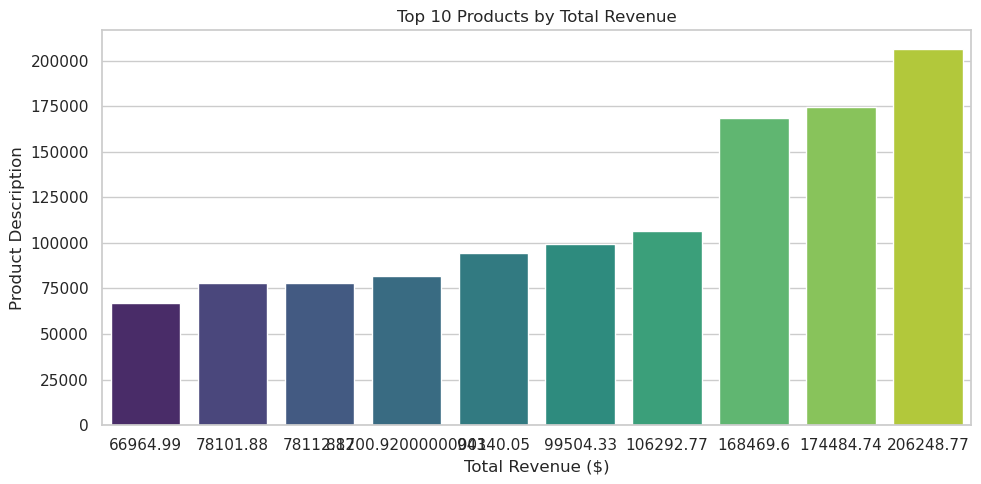

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
top_product=df.groupby('Description')['TotalAmount'].sum().nlargest(10)
top_product

plt.figure(figsize=(10,5))
sns.barplot(x=top_product.values,y=top_product.values,palette='viridis')
plt.title('Top 10 Products by Total Revenue')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Product Description')
plt.tight_layout()
plt.savefig('top_10_products.png')
plt.show()

<ipython-input-50-0420f2ae2fab>:16: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('monthly_sales_trend.png')
<ipython-input-50-0420f2ae2fab>:16: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('monthly_sales_trend.png')
<ipython-input-50-0420f2ae2fab>:16: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('monthly_sales_trend.png')
<ipython-input-50-0420f2ae2fab>:16: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('monthly_sales_trend.png')
<ipython-input-50-0420f2ae2fab>:16: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be rem

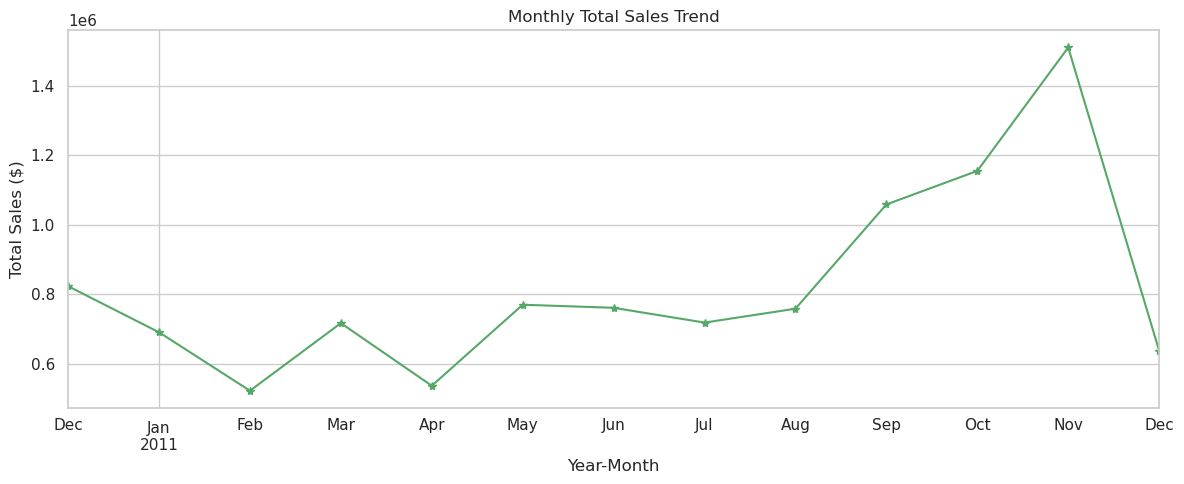

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

monthly_sales=df.groupby('YearMonth')['TotalAmount'].sum()

plt.figure(figsize=(12,5))
monthly_sales.plot(kind='line',marker='*',color='g')

plt.title('Monthly Total Sales Trend')
plt.xlabel('Year-Month')
plt.ylabel('Total Sales ($)')
plt.grid(True)

plt.savefig('monthly_sales_trend.png')
plt.tight_layout()
plt.show()

<ipython-input-51-e18a1cba234c>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='magma')
<ipython-input-51-e18a1cba234c>:9: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('top_countries.png')
<ipython-input-51-e18a1cba234c>:9: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('top_countries.png')


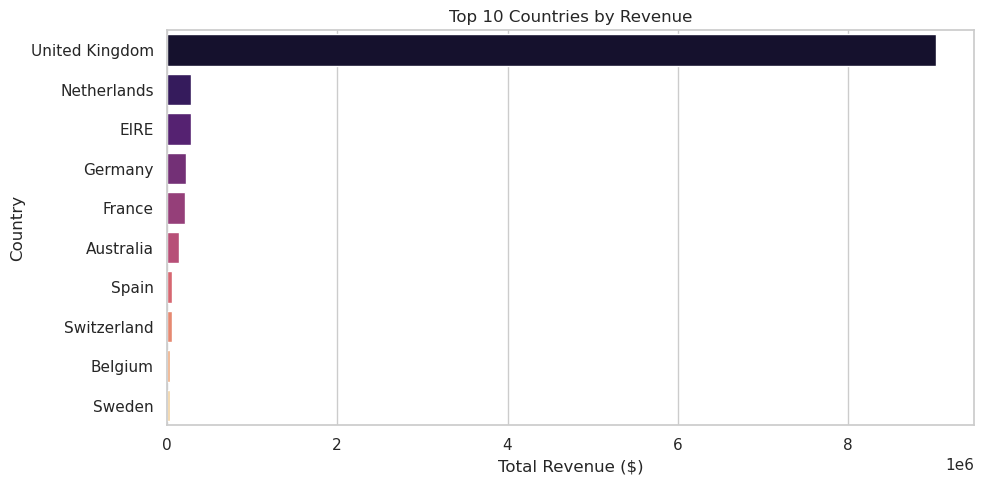

In [51]:
top_countries = df.groupby('Country')['TotalAmount'].sum().nlargest(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='magma')
plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue ($)')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('top_countries.png')
plt.show()